# Milestone 2: Data Cleaning and Preparation

## Step 1: Import relevant libraries

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)
sns.set_theme(style='whitegrid')

print("All libraries imported successfully!")

All libraries imported successfully!


## Step 2: Loading the datasets

In [3]:
RAW_DIR = '../data/raw'
CLEAN_DIR = '../data/clean'
os.makedirs(CLEAN_DIR, exist_ok=True)

stores = pd.read_csv(f'{RAW_DIR}/stores.csv')
products = pd.read_csv(f'{RAW_DIR}/products.csv')
promotions = pd.read_csv(f'{RAW_DIR}/promotions.csv')
customers = pd.read_csv(f'{RAW_DIR}/customers.csv', dtype={'phone': str})
transactions = pd.read_csv(f'{RAW_DIR}/transactions.csv')

# keep untouched copies so we can compare before and after
raw_customers = customers.copy()
raw_transactions = transactions.copy()

In [4]:
transactions.head(5)

,transaction_id,invoice_no,transaction_date,store_id,customer_id,product_id,quantity,unit_price_kes,discount_pct,promo_id,payment_method,line_total_kes,channel
0,1,INV100001,2022-01-01,ST018,C2646,P224,1,216.0,0,NaN,Cash,216.0,In-store
1,2,INV100001,2022-01-01,ST018,C2646,P132,3,357.0,0,NaN,Cash,1071.0,In-store
2,3,INV100002,2022-01-01,ST028,C1767,P093,3,757.0,0,NaN,Cash,2271.0,In-store
3,4,INV100002,2022-01-01,ST028,C1767,P236,1,115.0,0,NaN,Cash,115.0,In-store
4,5,INV100003,01/01/2022,ST037,C0200,P143,3,120.0,0,NaN,M-Pesa,360.0,In-store


In [5]:
customers.head(5)

,customer_id,first_name,last_name,gender,date_of_birth,phone,email,county,signup_date,preferred_payment,loyalty_member
0,C0001,Ali,Cheruiyot,Male,1999-01-24,+254729641823,ali.cheruiyot98@gmail.com,Nairobi,2019-07-05,M-Pesa,No
1,C0002,Caroline,Langat,Female,1983-09-10,+254750805381,caroline.langat2@outlook.com,Nakuru,2019-07-05,M-Pesa,No
2,C0003,Dennis,Rotich,Male,1985-06-13,+254701882788,dennis.rotich75@yahoo.com,Nairobi,2019-09-11,M-Pesa,Yes
3,C0004,Esther,Ndung'u,Female,1977-05-15,+254780408717,esther.ndungu5@gmail.com,Nairobi,2023-11-07,M-Pesa,Yes
4,C0005,Joseph,Chebet,Male,1987-02-21,+254139862503,joseph.chebet90@gmail.com,Nairobi,2021-08-24,Cash,No


In [6]:
display(stores.head(5))
display(products.head(5))
display(promotions.head(5))

,store_id,store_name,county,town,store_type,opening_date,floor_area_sqm,latitude,longitude,manager_name
0,ST001,Karen Kiosk,Nairobi,Karen,Kiosk,2015-09-16,72,-1.262625,36.774035,Agnes Njoroge
1,ST002,Embakasi Supermarket,Nairobi,Embakasi,Supermarket,2022-11-22,704,-1.295243,36.782954,Lucy Kamau
2,ST003,Kasarani Kiosk,Nairobi,Kasarani,Kiosk,2023-06-09,100,-1.259385,36.835272,Collins Hussein
3,ST004,South B Mini-mart,Nairobi,South B,Mini-mart,2013-07-17,222,-1.311612,36.776311,Zainab Kamau
4,ST005,Westlands Supermarket,Nairobi,Westlands,Supermarket,2016-09-11,1155,-1.327224,36.849530,Hassan Naliaka


,product_id,product_name,category,subcategory,brand,unit_cost_kes,unit_price_kes,supplier,is_perishable
0,P001,Alpenliebe Sweets Single,Snacks,Sweets,Alpenliebe,94.25,135.0,Coastal Supplies Ltd,No
1,P002,Nunu Evaporated Milk 170g,Dairy,Evaporated Milk,Nunu,148.29,185.0,Rift Valley Wholesalers,No
2,P003,Festive Bread 400g,Food Staples,Bread,Festive,90.11,117.0,Safari Provisions,Yes
3,P004,Daima Yoghurt 250ml,Dairy,Yoghurt,Daima,53.61,65.0,Savannah Distributors,Yes
4,P005,Monster Energy Drink 500ml,Beverages,Energy Drink,Monster,282.45,396.0,Lakeside Traders,No


,promo_id,promo_name,start_date,end_date,discount_pct,category_targeted
0,PR01,Back-to-School,2022-01-03,2022-01-14,10,Household
1,PR02,Black Friday,2022-11-21,2022-11-27,25,All
2,PR03,Back-to-School,2023-01-02,2023-01-13,12,Household
3,PR04,Easter Offer,2023-04-03,2023-04-10,10,Food Staples
4,PR05,Mid-Year Sale,2023-07-03,2023-07-14,15,Personal Care


# Load the KNBS population census data

In [35]:

knbs_path = f'{RAW_DIR}/2019-population_census-report-per-county.csv'

if os.path.exists(knbs_path):
    knbs = pd.read_csv(knbs_path)

    print("KNBS dataset loaded successfully!")
    print("Dataset shape:", knbs.shape)
    display(knbs.head(10))
    print(knbs.dtypes)

else:
    print(f"KNBS file not found at: {knbs_path}")


KNBS dataset loaded successfully!
Dataset shape: (47, 11)


,County,Total_Population19,Male populatio 2019,Female population 2019,Households,Av_HH_Size,LandArea,Population Density,Population in 2009,Pop_change,Intersex population 2019
0,Baringo,"666,763","336,322","330,428","142,518",5,"10,976",61,"555,561","111,202",13
1,Bomet,"875,689","434,287","441,379","187,641",5,"2,531",346,"724,186","151,503",23
2,Bungoma,"1,670,570","812,146","858,389","358,796",5,"3,024",552,"1,630,934","39,636",35
3,Busia,"893,681","426,252","467,401","198,152",5,"1,696",527,"488,075","405,606",28
4,Elgeyo-Marakwet,"454,480","227,317","227,151","99,861",5,"3,032",150,"369,998","84,482",12
5,Embu,"608,599","304,208","304,367","182,743",3,"2,821",216,"516,212","92,387",24
6,Garissa,"841,353","458,975","382,344","141,394",6,"44,736",19,"623,060","218,293",34
7,Homa Bay,"1,131,950","539,560","592,367","262,036",4,"3,153",359,"963,794","168,156",23
8,Isiolo,"268,002","139,510","128,483","58,072",5,"25,350",11,"143,294","124,708",9
9,Kajiado,"1,117,840","557,098","560,704","316,179",4,"21,871",51,"687,312","430,528",38


County                        str
Total_Population19            str
Male populatio 2019           str
Female population 2019        str
Households                    str
Av_HH_Size                  int64
LandArea                      str
Population Density            str
Population in 2009            str
Pop_change                    str
Intersex population 2019    int64
dtype: object


__a small log, so every cleaning step records what it changed__ 
This becomes the before/after evidence

In [8]:
log_rows = []

def log_step(table, step, values_fixed=None, rows_before=None, rows_after=None, note=''):
    log_rows.append(dict(table=table, step=step, rows_before=rows_before, rows_after=rows_after,
                         values_fixed=values_fixed, note=note))
    msg = f'[{table}] {step}'
    if rows_before is not None:
        msg += f': {rows_before:,} -> {rows_after:,} rows'
    if values_fixed is not None:
        msg += f': {int(values_fixed):,} values fixed'
    print(msg, note)

## Step 3: Pre-Cleaning checks

In [9]:
def basic_checks(data, name=''):
    print('=' * 25, name, '=' * 25)
    print('shape:', data.shape)
    print('duplicate rows:', data.duplicated().sum())
    print('missing values per column (only columns with missing values):')
    missing = data.isnull().sum()
    print(missing[missing > 0].to_string() if (missing > 0).any() else 'none')
    display(data.describe().T)
    cat = data.select_dtypes(include=['object', 'string'])
    if cat.shape[1] > 0:
        display(cat.describe().T)

In [10]:
basic_checks(transactions, 'transactions (raw)')

========================= transactions (raw) =========================
shape: (252500, 13)
duplicate rows: 2500
missing values per column (only columns with missing values):
transaction_date      3766
customer_id           9047
promo_id            243112


,count,mean,std,min,25%,50%,75%,max
transaction_id,252500.0,124992.349549,72171.984953,1.0,62491.75,124978.5,187504.25,250000.0
quantity,252500.0,2.207691,9.964135,-3.0,1.00,2.0,2.00,499.0
unit_price_kes,252500.0,429.210459,394.325787,21.0,196.00,300.0,551.00,17170.0
discount_pct,252500.0,1.013952,4.477625,0.0,0.00,0.0,0.00,30.0
line_total_kes,252500.0,941.678131,5696.282394,-16340.0,279.00,532.0,972.00,891275.0


,count,unique,top,freq
invoice_no,252500,88647,INV146682,12
transaction_date,248734,2738,2023-11-26,376
store_id,252500,40,ST036,8619
customer_id,243453,4605,C1023,568
product_id,252500,300,P252,7389
promo_id,9388,12,PR10,2429
payment_method,252500,4,M-Pesa,154778
channel,252500,3,In-store,200416


In [11]:
basic_checks(customers, 'customers (raw)')

========================= customers (raw) =========================
shape: (5015, 11)
duplicate rows: 15
missing values per column (only columns with missing values):
gender           136
date_of_birth     81
phone            144
email            534


,count,unique,top,freq
customer_id,5015,5000,C0037,2
first_name,5015,48,Linet,132
last_name,5015,39,Chebet,157
gender,4879,2,Female,2447
date_of_birth,4934,4362,1900-01-01,11
phone,4871,4857,+254167482498,2
email,4481,4449,lucy.chebet59@outlook.com,2
county,5015,63,Nairobi,1462
signup_date,5015,2044,2020-02-01,9
preferred_payment,5015,4,M-Pesa,2737


,count,unique,top,freq
customer_id,5015,5000,C0037,2
first_name,5015,48,Linet,132
last_name,5015,39,Chebet,157
gender,4879,2,Female,2447
date_of_birth,4934,4362,1900-01-01,11
phone,4871,4857,+254167482498,2
email,4481,4449,lucy.chebet59@outlook.com,2
county,5015,63,Nairobi,1462
signup_date,5015,2044,2020-02-01,9
preferred_payment,5015,4,M-Pesa,2737


In [36]:
basic_checks(knbs, 'KNBS population census (raw)')

========================= KNBS population census (raw) =========================
shape: (47, 11)
duplicate rows: 0
missing values per column (only columns with missing values):
none


,count,mean,std,min,25%,50%,75%,max
Av_HH_Size,47.0,4.340426,0.938931,3.0,4.0,4.0,5.0,7.0
Intersex population 2019,47.0,32.425532,38.490961,2.0,18.0,25.0,34.0,245.0


,count,unique,top,freq
County,47,47,Baringo,1
Total_Population19,47,47,"666,763",1
Male populatio 2019,47,47,"336,322",1
Female population 2019,47,47,"330,428",1
Households,47,47,"142,518",1
LandArea,47,47,"10,976",1
Population Density,47,46,14,2
Population in 2009,47,47,"555,561",1
Pop_change,47,47,"111,202",1


In [37]:
# Exploring  the raw KNBS data

print("Column names:")
print(knbs.columns.tolist())

print("\nData types:")
display(knbs.dtypes.to_frame("data_type"))

print("\nFirst 10 rows:")
display(knbs.head(10))

print("\nSummary statistics:")
display(knbs.describe(include="all").T)

Column names:
['County', 'Total_Population19', 'Male populatio 2019', 'Female population 2019', 'Households', 'Av_HH_Size', 'LandArea', 'Population Density', 'Population in 2009', 'Pop_change', 'Intersex population 2019']

Data types:


,data_type
County,str
Total_Population19,str
Male populatio 2019,str
Female population 2019,str
Households,str
Av_HH_Size,int64
LandArea,str
Population Density,str
Population in 2009,str
Pop_change,str



First 10 rows:


,County,Total_Population19,Male populatio 2019,Female population 2019,Households,Av_HH_Size,LandArea,Population Density,Population in 2009,Pop_change,Intersex population 2019
0,Baringo,"666,763","336,322","330,428","142,518",5,"10,976",61,"555,561","111,202",13
1,Bomet,"875,689","434,287","441,379","187,641",5,"2,531",346,"724,186","151,503",23
2,Bungoma,"1,670,570","812,146","858,389","358,796",5,"3,024",552,"1,630,934","39,636",35
3,Busia,"893,681","426,252","467,401","198,152",5,"1,696",527,"488,075","405,606",28
4,Elgeyo-Marakwet,"454,480","227,317","227,151","99,861",5,"3,032",150,"369,998","84,482",12
5,Embu,"608,599","304,208","304,367","182,743",3,"2,821",216,"516,212","92,387",24
6,Garissa,"841,353","458,975","382,344","141,394",6,"44,736",19,"623,060","218,293",34
7,Homa Bay,"1,131,950","539,560","592,367","262,036",4,"3,153",359,"963,794","168,156",23
8,Isiolo,"268,002","139,510","128,483","58,072",5,"25,350",11,"143,294","124,708",9
9,Kajiado,"1,117,840","557,098","560,704","316,179",4,"21,871",51,"687,312","430,528",38



Summary statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
County,47,47,Baringo,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Total_Population19,47,47,"666,763",1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Male populatio 2019,47,47,"336,322",1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Female population 2019,47,47,"330,428",1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Households,47,47,"142,518",1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Av_HH_Size,47.0,NaN,NaN,NaN,4.340426,0.938931,3.0,4.0,4.0,5.0,7.0
LandArea,47,47,"10,976",1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Population Density,47,46,14,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Population in 2009,47,47,"555,561",1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Pop_change,47,47,"111,202",1,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [38]:
# Inspecting sample values in columns stored as strings
string_cols = knbs.select_dtypes(include=["object", "string"]).columns

for col in string_cols:
    print(f"\n{col}")
    print(knbs[col].head(10).tolist())


County
['Baringo', 'Bomet', 'Bungoma', 'Busia', 'Elgeyo-Marakwet', 'Embu', 'Garissa', 'Homa Bay', 'Isiolo', 'Kajiado']

Total_Population19
[' 666,763 ', ' 875,689 ', ' 1,670,570 ', ' 893,681 ', ' 454,480 ', ' 608,599 ', ' 841,353 ', ' 1,131,950 ', ' 268,002 ', ' 1,117,840 ']

Male populatio 2019
[' 336,322 ', ' 434,287 ', ' 812,146 ', ' 426,252 ', ' 227,317 ', ' 304,208 ', ' 458,975 ', ' 539,560 ', ' 139,510 ', ' 557,098 ']

Female population 2019
[' 330,428 ', ' 441,379 ', ' 858,389 ', ' 467,401 ', ' 227,151 ', ' 304,367 ', ' 382,344 ', ' 592,367 ', ' 128,483 ', ' 560,704 ']

Households
[' 142,518 ', ' 187,641 ', ' 358,796 ', ' 198,152 ', ' 99,861 ', ' 182,743 ', ' 141,394 ', ' 262,036 ', ' 58,072 ', ' 316,179 ']

LandArea
[' 10,976 ', ' 2,531 ', ' 3,024 ', ' 1,696 ', ' 3,032 ', ' 2,821 ', ' 44,736 ', ' 3,153 ', ' 25,350 ', ' 21,871 ']

Population Density
[' 61 ', ' 346 ', ' 552 ', ' 527 ', ' 150 ', ' 216 ', ' 19 ', ' 359 ', ' 11 ', ' 51 ']

Population in 2009
[' 555,561 ', ' 724,186

In [12]:
basic_checks(stores, 'stores (raw)')
basic_checks(products, 'products (raw)')
basic_checks(promotions, 'promotions (raw)')

========================= stores (raw) =========================
shape: (40, 10)
duplicate rows: 0
missing values per column (only columns with missing values):
none


,count,mean,std,min,25%,50%,75%,max
floor_area_sqm,40.0,559.325000,442.511097,47.000000,196.500000,369.500000,1037.750000,1466.000000
latitude,40.0,-1.149317,1.264396,-4.088274,-1.341516,-1.142546,-0.321811,0.567299
longitude,40.0,36.896277,1.440447,34.681634,36.032884,36.809826,37.250084,39.800657


,count,unique,top,freq
store_id,40,40,ST001,1
store_name,40,40,Karen Kiosk,1
county,40,15,Nairobi,11
town,40,40,Karen,1
store_type,40,3,Supermarket,19
opening_date,40,40,2015-09-16,1
manager_name,40,39,Eric Wambui,2


========================= products (raw) =========================
shape: (300, 9)
duplicate rows: 0
missing values per column (only columns with missing values):
none


,count,mean,std,min,25%,50%,75%,max
unit_cost_kes,300.0,314.894767,307.898812,17.79,128.505,224.505,406.675,2783.07
unit_price_kes,300.0,409.680000,403.392799,21.00,165.750,287.000,535.000,3755.00


,count,unique,top,freq
product_id,300,300,P001,1
product_name,300,300,Alpenliebe Sweets Single,1
category,300,6,Snacks,50
subcategory,300,50,Soda,14
brand,300,118,Brookside,17
supplier,300,8,Savannah Distributors,47
is_perishable,300,2,No,253


========================= promotions (raw) =========================
shape: (12, 6)
duplicate rows: 0
missing values per column (only columns with missing values):
none


,count,mean,std,min,25%,50%,75%,max
discount_pct,12.0,15.166667,7.334022,8.0,10.0,12.0,17.5,30.0


,count,unique,top,freq
promo_id,12,12,PR01,1
promo_name,12,5,Back-to-School,3
start_date,12,12,2022-01-03,1
end_date,12,12,2022-01-14,1
category_targeted,12,7,All,3


### Problems spotted in transactions

In [13]:
dates = transactions['transaction_date'].astype('string')
print('blank dates               :', dates.isna().sum())
print('dd/mm/yyyy format dates   :', dates.str.contains('/', na=False).sum())
print('yyyy-mm-dd format dates   :', dates.str.match(r'\d{4}-\d{2}-\d{2}', na=False).sum())
print('quantity above 12         :', (transactions['quantity'] > 12).sum())
print('negative quantity (returns):', (transactions['quantity'] < 0).sum())
print('blank customer_id (walk-ins):', transactions['customer_id'].isna().sum())
print('duplicate rows            :', transactions.duplicated().sum())

blank dates               : 3766
dd/mm/yyyy format dates   : 12521
yyyy-mm-dd format dates   : 236213
quantity above 12         : 241
negative quantity (returns): 1305
blank customer_id (walk-ins): 9047
duplicate rows            : 2500


### Problems spotted in customers

In [14]:
print('distinct county spellings  :', customers['county'].nunique(), '(should be 15)')
print(customers['county'].value_counts().head(25).to_string())
print()
print('local-format phones (07..) :', customers['phone'].str.startswith('0', na=False).sum())
print('blank gender               :', customers['gender'].isna().sum())
print('blank date of birth        :', customers['date_of_birth'].isna().sum())
dob = pd.to_datetime(customers['date_of_birth'], errors='coerce')
print('birth dates before 1920    :', (dob < '1920-01-01').sum())
print('duplicate customer rows    :', customers.duplicated().sum())

distinct county spellings  : 63 (should be 15)
county
Nairobi        1462
Mombasa         493
Kiambu          437
Nakuru          340
Kisumu          312
Uasin Gishu     308
Machakos        240
Kajiado         192
Kakamega        163
Nyeri           161
Meru            147
Kilifi          147
Kisii           135
Garissa         101
Embu             85
Nairobi          32
Nrb              25
NAIROBI          21
nairobi          20
Kiambu           13
NAKURU           11
Msa              11
nakuru           10
kisumu            9
mombasa           9

local-format phones (07..) : 519
blank gender               : 136
blank date of birth        : 81
birth dates before 1920    : 11
duplicate customer rows    : 15


## Step 4: Data Cleaning

### 4.1 Transactions

__drop exact duplicate rows__

In [15]:
n_before = len(transactions)
transactions = transactions.drop_duplicates()
log_step('transactions', 'drop exact duplicate rows', rows_before=n_before, rows_after=len(transactions))
assert transactions['transaction_id'].is_unique

[transactions] drop exact duplicate rows: 252,500 -> 250,000 rows 


__setting the correct data types for numeric columns__

In [16]:
for col in ['transaction_id', 'quantity', 'discount_pct']:
    transactions[col] = pd.to_numeric(transactions[col], errors='raise').astype(int)
for col in ['unit_price_kes', 'line_total_kes']:
    transactions[col] = pd.to_numeric(transactions[col], errors='raise')
transactions.dtypes

transaction_id        int64
invoice_no              str
transaction_date        str
store_id                str
customer_id             str
product_id              str
quantity              int64
unit_price_kes      float64
discount_pct          int64
promo_id                str
payment_method          str
line_total_kes      float64
channel                 str
dtype: object

__Date Formats__

In [17]:
def parse_mixed_dates(s):
    s = s.astype('string').str.strip()
    out = pd.Series(pd.NaT, index=s.index, dtype='datetime64[ns]')
    slash = s.str.contains('/', na=False)
    iso = s.notna() & ~slash
    out[iso] = pd.to_datetime(s[iso], format='%Y-%m-%d', errors='coerce')
    out[slash] = pd.to_datetime(s[slash], format='%d/%m/%Y', errors='coerce')
    return out

n_slash = transactions['transaction_date'].astype('string').str.contains('/', na=False).sum()
transactions['transaction_date'] = parse_mixed_dates(transactions['transaction_date'])
log_step('transactions', 'parse dd/mm/yyyy dates to one date type', values_fixed=n_slash)

[transactions] parse dd/mm/yyyy dates to one date type: 12,403 values fixed 


__filling in the blank dates__

In [18]:
was_blank = transactions['transaction_date'].isna()
transactions['date_imputed'] = was_blank

# step 1: another line of the same invoice
transactions['transaction_date'] = transactions['transaction_date'].fillna(
    transactions.groupby('invoice_no')['transaction_date'].transform('first'))
fixed_step1 = was_blank.sum() - transactions['transaction_date'].isna().sum()

# step 2: neighbouring invoice (invoice numbers are in date order)
inv = (transactions.groupby('invoice_no', as_index=False)['transaction_date'].first()
       .assign(num=lambda d: d['invoice_no'].str[3:].astype(int))
       .sort_values('num'))
inv['transaction_date'] = inv['transaction_date'].ffill().bfill()
transactions['transaction_date'] = transactions['transaction_date'].fillna(
    transactions['invoice_no'].map(inv.set_index('invoice_no')['transaction_date']))

log_step('transactions', 'fill blank dates from the same invoice', values_fixed=fixed_step1)
log_step('transactions', 'fill remaining blank dates from the neighbouring invoice (approximate)',
         values_fixed=was_blank.sum() - fixed_step1)
assert transactions['transaction_date'].notna().all()

[transactions] fill blank dates from the same invoice: 3,502 values fixed 
[transactions] fill remaining blank dates from the neighbouring invoice (approximate): 236 values fixed 


__handling the outliers__

In [19]:
transactions['year'] = transactions['transaction_date'].dt.year

big_q = transactions['quantity'] > 12
median_q = (transactions[(transactions['quantity'] > 0) & ~big_q]
            .groupby('product_id')['quantity'].median().round().clip(lower=1))
transactions.loc[big_q, 'quantity'] = transactions.loc[big_q, 'product_id'].map(median_q).fillna(1).astype(int)

median_p = transactions.groupby(['product_id', 'year'])['unit_price_kes'].transform('median')
big_p = transactions['unit_price_kes'] > 3 * median_p
transactions.loc[big_p, 'unit_price_kes'] = median_p[big_p]

transactions['outlier_fixed'] = big_q | big_p
log_step('transactions', 'replace quantity outliers (above 12) with the product median', values_fixed=big_q.sum())
log_step('transactions', 'replace price outliers (above 3x product-year median) with the median', values_fixed=big_p.sum())

[transactions] replace quantity outliers (above 12) with the product median: 239 values fixed 
[transactions] replace price outliers (above 3x product-year median) with the median: 123 values fixed 


__recomputing the line total for the corrected rows, and check that every other row was already correct__

In [20]:
expected_total = np.round(transactions['quantity'] * transactions['unit_price_kes']
                          * (1 - transactions['discount_pct'] / 100), 2)
wrong_untouched = (~transactions['outlier_fixed']) & ((expected_total - transactions['line_total_kes']).abs() > 0.01)
transactions['line_total_kes'] = expected_total
log_step('transactions', 'recompute line_total for corrected rows', values_fixed=transactions['outlier_fixed'].sum(),
         note=f'(untouched rows with a wrong total: {int(wrong_untouched.sum())})')

[transactions] recompute line_total for corrected rows: 362 values fixed (untouched rows with a wrong total: 0)


__flag walk-ins and returns, and create features__

Walk-in sales (no customer) and returns are real events, so they are flagged instead of removed.

In [21]:
d = transactions['transaction_date']
transactions['is_walkin'] = transactions['customer_id'].isna()
transactions['is_return'] = transactions['quantity'] < 0
transactions['on_promo'] = transactions['promo_id'].notna()
transactions['month'] = d.dt.month
transactions['day_of_week'] = d.dt.day_name()
transactions['is_weekend'] = d.dt.dayofweek >= 5
transactions['is_payday_period'] = d.dt.day >= 25   # salary days at month end
transactions = transactions.sort_values('transaction_id').reset_index(drop=True)
transactions.head()

,transaction_id,invoice_no,transaction_date,store_id,customer_id,product_id,quantity,unit_price_kes,discount_pct,promo_id,payment_method,line_total_kes,channel,date_imputed,year,outlier_fixed,is_walkin,is_return,on_promo,month,day_of_week,is_weekend,is_payday_period
0,1,INV100001,2022-01-01,ST018,C2646,P224,1,216.0,0,NaN,Cash,216.0,In-store,False,2022,False,False,False,False,1,Saturday,True,False
1,2,INV100001,2022-01-01,ST018,C2646,P132,3,357.0,0,NaN,Cash,1071.0,In-store,False,2022,False,False,False,False,1,Saturday,True,False
2,3,INV100002,2022-01-01,ST028,C1767,P093,3,757.0,0,NaN,Cash,2271.0,In-store,False,2022,False,False,False,False,1,Saturday,True,False
3,4,INV100002,2022-01-01,ST028,C1767,P236,1,115.0,0,NaN,Cash,115.0,In-store,False,2022,False,False,False,False,1,Saturday,True,False
4,5,INV100003,2022-01-01,ST037,C0200,P143,3,120.0,0,NaN,M-Pesa,360.0,In-store,False,2022,False,False,False,False,1,Saturday,True,False


### 4.2 Customers

__drop exact duplicate rows__

In [22]:
n_before = len(customers)
customers = customers.drop_duplicates()
log_step('customers', 'drop exact duplicate rows', rows_before=n_before, rows_after=len(customers))
assert customers['customer_id'].is_unique

[customers] drop exact duplicate rows: 5,015 -> 5,000 rows 


__standardizing the county names__

In [23]:
COUNTIES = ['Nairobi', 'Mombasa', 'Kisumu', 'Nakuru', 'Uasin Gishu', 'Kiambu', 'Machakos', 'Kajiado',
            'Nyeri', 'Meru', 'Kakamega', 'Kisii', 'Kilifi', 'Embu', 'Garissa']
COUNTY_FIXES = {'nrb': 'Nairobi', 'msa': 'Mombasa', 'u. gishu': 'Uasin Gishu', 'nkr': 'Nakuru'}

county_before = customers['county'].copy()
county_key = customers['county'].astype('string').str.strip().str.lower()
customers['county'] = county_key.map(COUNTY_FIXES).fillna(county_key.str.title())
assert customers['county'].isin(COUNTIES).all()
log_step('customers', 'standardise county names', values_fixed=(county_before != customers['county']).sum())

[customers] standardise county names: 292 values fixed 


__Standardizing phone numbers one format (+254...)__

In [24]:
def clean_phone(p):
    if pd.isna(p):
        return p
    p = str(p).strip()
    return '+254' + p[1:] if p.startswith('0') else p

phone_before = customers['phone'].copy()
customers['phone'] = customers['phone'].map(clean_phone)
log_step('customers', 'convert local 07.. phone numbers to +254 format',
         values_fixed=(phone_before.notna() & (phone_before != customers['phone'])).sum())

[customers] convert local 07.. phone numbers to +254 format: 517 values fixed 


__handling missing values__

In [25]:
log_step('customers', "fill blank gender with 'Unknown'", values_fixed=customers['gender'].isna().sum())
customers['gender'] = customers['gender'].fillna('Unknown')
customers.isnull().sum()

[customers] fill blank gender with 'Unknown': 135 values fixed 


customer_id            0
first_name             0
last_name              0
gender                 0
date_of_birth         81
phone                143
email                532
county                 0
signup_date            0
preferred_payment      0
loyalty_member         0
dtype: int64

__fixing dates and create age, tenure and other features__

In [26]:
REF_DATE = pd.Timestamp('2025-09-30')

customers['date_of_birth'] = pd.to_datetime(customers['date_of_birth'], errors='coerce')
impossible = customers['date_of_birth'] < pd.Timestamp('1920-01-01')
customers.loc[impossible, 'date_of_birth'] = pd.NaT
log_step('customers', 'set impossible birth dates (before 1920) to blank', values_fixed=impossible.sum())

customers['signup_date'] = pd.to_datetime(customers['signup_date'], errors='raise')
customers['age'] = ((REF_DATE - customers['date_of_birth']).dt.days // 365.25).astype('Int64')
customers['age_band'] = (pd.cut(customers['age'].astype(float), [0, 24, 34, 44, 54, 64, 120],
                                labels=['18-24', '25-34', '35-44', '45-54', '55-64', '65+'])
                         .astype('string').fillna('Unknown'))
customers['tenure_days'] = (REF_DATE - customers['signup_date']).dt.days
customers['has_email'] = customers['email'].notna()
customers['loyalty_member'] = customers['loyalty_member'].eq('Yes')
customers = customers.reset_index(drop=True)
customers.head()

[customers] set impossible birth dates (before 1920) to blank: 11 values fixed 


,customer_id,first_name,last_name,gender,date_of_birth,phone,email,county,signup_date,preferred_payment,loyalty_member,age,age_band,tenure_days,has_email
0,C0001,Ali,Cheruiyot,Male,1999-01-24,+254729641823,ali.cheruiyot98@gmail.com,Nairobi,2019-07-05,M-Pesa,False,26,25-34,2279,True
1,C0002,Caroline,Langat,Female,1983-09-10,+254750805381,caroline.langat2@outlook.com,Nakuru,2019-07-05,M-Pesa,False,42,35-44,2279,True
2,C0003,Dennis,Rotich,Male,1985-06-13,+254701882788,dennis.rotich75@yahoo.com,Nairobi,2019-09-11,M-Pesa,True,40,35-44,2211,True
3,C0004,Esther,Ndung'u,Female,1977-05-15,+254780408717,esther.ndungu5@gmail.com,Nairobi,2023-11-07,M-Pesa,True,48,45-54,693,True
4,C0005,Joseph,Chebet,Male,1987-02-21,+254139862503,joseph.chebet90@gmail.com,Nairobi,2021-08-24,Cash,False,38,35-44,1498,True


### 4.3 Stores, products and promotions
These tables had no duplicates or missing values.

In [27]:
assert stores['store_id'].is_unique and stores.notna().all().all()
assert stores['county'].isin(COUNTIES).all()
stores['opening_date'] = pd.to_datetime(stores['opening_date'])

assert products['product_id'].is_unique and products.notna().all().all()
assert (products['unit_price_kes'] > products['unit_cost_kes']).all()
products['margin_pct'] = ((products['unit_price_kes'] - products['unit_cost_kes']) / products['unit_price_kes'] * 100).round(1)
products['is_perishable'] = products['is_perishable'].eq('Yes')

assert promotions['promo_id'].is_unique and promotions.notna().all().all()
promotions['start_date'] = pd.to_datetime(promotions['start_date'])
promotions['end_date'] = pd.to_datetime(promotions['end_date'])
assert (promotions['end_date'] >= promotions['start_date']).all()
promotions['duration_days'] = (promotions['end_date'] - promotions['start_date']).dt.days + 1

log_step('stores', 'validate keys, counties and missing values', rows_before=len(stores), rows_after=len(stores))
log_step('products', 'validate keys, prices and missing values; add margin_pct', rows_before=len(products), rows_after=len(products))
log_step('promotions', 'validate keys and dates; add duration_days', rows_before=len(promotions), rows_after=len(promotions))

[stores] validate keys, counties and missing values: 40 -> 40 rows 
[products] validate keys, prices and missing values; add margin_pct: 300 -> 300 rows 
[promotions] validate keys and dates; add duration_days: 12 -> 12 rows 


### 4.4 KNBS data
- KNBS data cleaning: Converted numeric columns stored as strings, removed
- extra spaces and thousands separators, and handled the parenthesized
- Mandera population-change value. No initial missing values or duplicates
- were detected. Outlier checks remain to be completed.

In [39]:

# Create a copy so the original KNBS data remains unchanged
knbs_clean = knbs.copy()

# Identify columns that should contain numeric values
numeric_cols = [
    "Total_Population19",
    "Male populatio 2019",
    "Female population 2019",
    "Households",
    "LandArea",
    "Population Density",
    "Population in 2009",
    "Pop_change"
]

# Remove surrounding spaces and thousands separators, then convert
for col in numeric_cols:
    knbs_clean[col] = pd.to_numeric(
        knbs_clean[col]
        .astype("string")
        .str.strip()
        .str.replace(",", "", regex=False),
        errors="coerce"
    )

# Display the resulting data types
print("Data types after conversion:")
display(knbs_clean.dtypes.to_frame("data_type"))

# Check for missing values introduced during conversion
print("Missing values after conversion:")
display(knbs_clean.isna().sum().to_frame("missing_values"))


Data types after conversion:


,data_type
County,str
Total_Population19,Int64
Male populatio 2019,Int64
Female population 2019,Int64
Households,Int64
Av_HH_Size,int64
LandArea,Int64
Population Density,Int64
Population in 2009,Int64
Pop_change,Int64


Missing values after conversion:


,missing_values
County,0
Total_Population19,0
Male populatio 2019,0
Female population 2019,0
Households,0
Av_HH_Size,0
LandArea,0
Population Density,0
Population in 2009,0
Pop_change,1


In [40]:

# Identify the row where Pop_change became missing
problem_rows = knbs_clean[knbs_clean["Pop_change"].isna()]

display(
    problem_rows[["County", "Pop_change"]]
)

# Compare the affected values with the original dataset
for idx in problem_rows.index:
    print("County:", knbs.loc[idx, "County"])
    print("Original Pop_change value:", repr(knbs.loc[idx, "Pop_change"]))


,County,Pop_change
23,Mandera,<NA>


County: Mandera
Original Pop_change value: ' (158,299)'


In [41]:

# Re-convert Pop_change, handling parentheses as negative values
pop_change = (
    knbs["Pop_change"]
    .astype("string")
    .str.strip()
)

# Convert values in parentheses to negative numbers
is_parenthesized = pop_change.str.match(r"^\(.*\)$", na=False)

pop_change = pop_change.str.replace(",", "", regex=False)
pop_change = pop_change.str.replace(r"[()]", "", regex=True)

knbs_clean["Pop_change"] = pd.to_numeric(
    pop_change, errors="coerce"
)

knbs_clean.loc[is_parenthesized, "Pop_change"] = (
    -knbs_clean.loc[is_parenthesized, "Pop_change"].abs()
)

# Validate the result for Mandera
display(
    knbs_clean.loc[
        knbs_clean["County"].eq("Mandera"),
        ["County", "Pop_change"]
    ]
)

print("Missing Pop_change values:", knbs_clean["Pop_change"].isna().sum())


,County,Pop_change
23,Mandera,-158299


Missing Pop_change values: 0


In [42]:
print("Cleaned dataset shape:", knbs_clean.shape)
print("Duplicate rows:", knbs_clean.duplicated().sum())
print("\nMissing values:")
display(knbs_clean.isna().sum().to_frame("missing_values"))

Cleaned dataset shape: (47, 11)
Duplicate rows: 0

Missing values:


,missing_values
County,0
Total_Population19,0
Male populatio 2019,0
Female population 2019,0
Households,0
Av_HH_Size,0
LandArea,0
Population Density,0
Population in 2009,0
Pop_change,0


## Step 5: Post-Cleaning checks

In [28]:
basic_checks(transactions, 'transactions (clean)')

========================= transactions (clean) =========================
shape: (250000, 23)
duplicate rows: 0
missing values per column (only columns with missing values):
customer_id      8946
promo_id       240726


,count,mean,min,25%,50%,75%,max,std
transaction_id,250000.0,125000.5,1.0,62500.75,125000.5,187500.25,250000.0,72168.927986
transaction_date,250000,2023-12-23 14:40:10.099200256,2022-01-01 00:00:00,2023-01-20 00:00:00,2023-12-31 00:00:00,2024-11-30 00:00:00,2025-09-30 00:00:00,NaN
quantity,250000.0,1.9208,-3.0,1.0,2.0,2.0,10.0,1.085912
unit_price_kes,250000.0,427.414822,21.0,195.0,300.0,551.0,4598.0,379.617066
discount_pct,250000.0,1.011892,0.0,0.0,0.0,0.0,30.0,4.472374
line_total_kes,250000.0,811.763926,-7137.0,279.0,531.0,969.0,24852.0,933.197075
year,250000.0,2023.478676,2022.0,2023.0,2023.0,2024.0,2025.0,1.072846
month,250000.0,6.49272,1.0,4.0,7.0,9.0,12.0,3.458074


,count,unique,top,freq
invoice_no,250000,88647,INV102172,11
store_id,250000,40,ST036,8519
customer_id,241054,4605,C4039,562
product_id,250000,300,P252,7325
promo_id,9274,12,PR10,2401
payment_method,250000,4,M-Pesa,153232
channel,250000,3,In-store,198411
day_of_week,250000,7,Saturday,42192


In [29]:
basic_checks(customers, 'customers (clean)')

========================= customers (clean) =========================
shape: (5000, 15)
duplicate rows: 0
missing values per column (only columns with missing values):
date_of_birth     92
phone            143
email            532
age               92


,count,mean,min,25%,50%,75%,max,std
date_of_birth,4908,1978-03-15 12:31:06.014669,1950-01-01 00:00:00,1964-01-19 18:00:00,1978-03-06 12:00:00,1992-05-06 12:00:00,2006-12-25 00:00:00,NaN
signup_date,5000,2021-11-09 02:01:32.160000,2019-01-01 00:00:00,2020-04-30 18:00:00,2021-07-29 00:00:00,2023-05-20 06:00:00,2025-06-27 00:00:00,NaN
age,4908.0,47.04564,18.0,33.0,47.0,61.0,75.0,16.349154
tenure_days,5000.0,1420.9156,95.0,863.75,1524.0,1978.25,2464.0,673.143373


,count,unique,top,freq
customer_id,5000,5000,C0001,1
first_name,5000,48,Linet,132
last_name,5000,39,Chebet,157
gender,5000,3,Female,2438
phone,4857,4857,+254729641823,1
email,4468,4449,lucy.chebet59@outlook.com,2
county,5000,15,Nairobi,1555
preferred_payment,5000,4,M-Pesa,2728
age_band,5000,7,55-64,930


__every foreign key must still point to a real row in its parent table__

In [30]:
assert transactions['store_id'].isin(stores['store_id']).all()
assert transactions['product_id'].isin(products['product_id']).all()
assert transactions['customer_id'].dropna().isin(customers['customer_id']).all()
assert transactions['promo_id'].dropna().isin(promotions['promo_id']).all()
assert transactions['transaction_date'].notna().all()
assert transactions.duplicated().sum() == 0

print('All integrity checks passed')
print('Date range:', transactions['transaction_date'].min().date(), 'to', transactions['transaction_date'].max().date())

All integrity checks passed
Date range: 2022-01-01 to 2025-09-30


In [43]:
# KNBS integrity checks
assert knbs_clean['County'].notna().all()
assert knbs_clean['County'].is_unique
assert knbs_clean['Total_Population19'].notna().all()
assert knbs_clean['Pop_change'].notna().all()

print('KNBS integrity checks passed')

KNBS integrity checks passed


__visual checks: outliers removed, counties standardized, dates repaired__

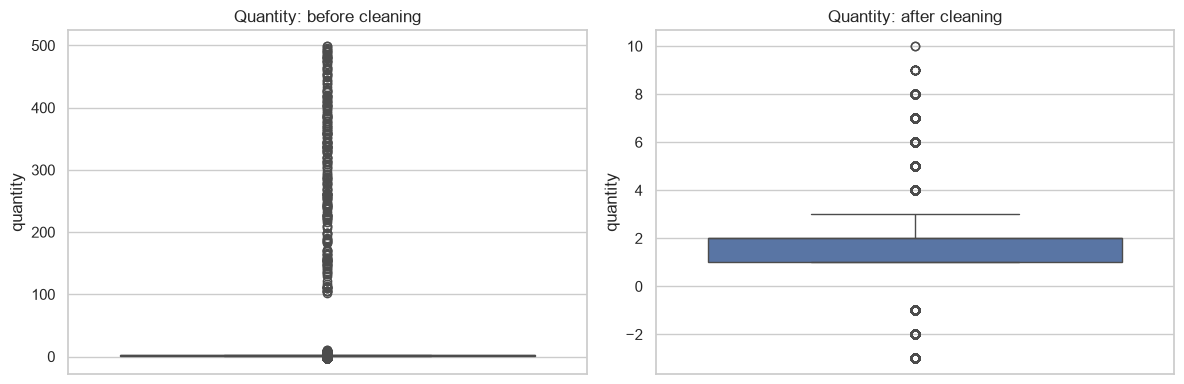

In [31]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(y=raw_transactions['quantity'], ax=ax[0]); ax[0].set_title('Quantity: before cleaning')
sns.boxplot(y=transactions['quantity'], ax=ax[1]); ax[1].set_title('Quantity: after cleaning')
plt.tight_layout(); plt.show()

distinct county spellings: 63 -> 15


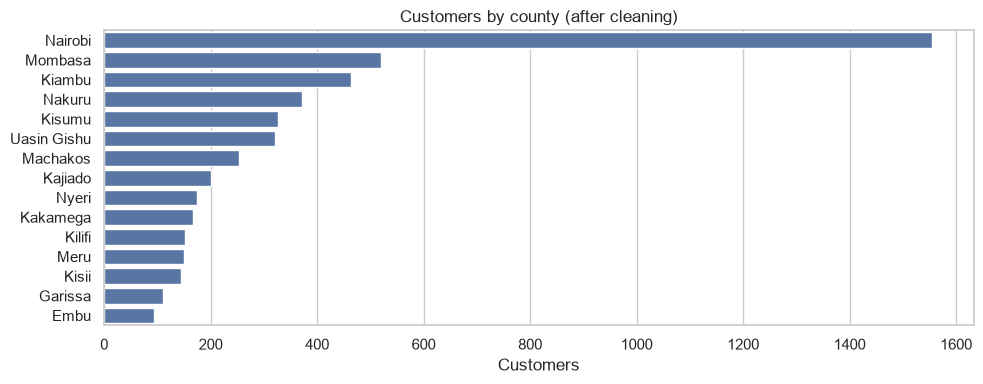

In [32]:
print('distinct county spellings:', raw_customers['county'].nunique(), '->', customers['county'].nunique())
plt.figure(figsize=(10, 4))
sns.countplot(data=customers, y='county', order=customers['county'].value_counts().index)
plt.title('Customers by county (after cleaning)'); plt.xlabel('Customers'); plt.ylabel('')
plt.tight_layout(); plt.show()

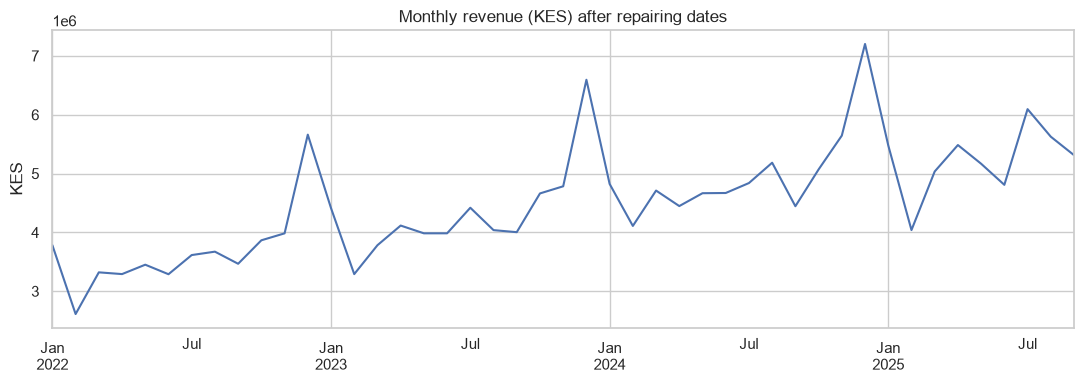

In [33]:
monthly = transactions.set_index('transaction_date')['line_total_kes'].resample('MS').sum()
plt.figure(figsize=(11, 4))
monthly.plot()
plt.title('Monthly revenue (KES) after repairing dates'); plt.xlabel(''); plt.ylabel('KES')
plt.tight_layout(); plt.show()

## Step 6: Saving the clean data and the cleaning log
The cleaning log is the before/after evidence for this milestone.

In [44]:

# Export all cleaned datasets
tables = {
    'stores': stores,
    'products': products,
    'promotions': promotions,
    'customers': customers,
    'transactions': transactions,
    'knbs': knbs_clean
}

for name, df in tables.items():
    df.to_csv(
        f'{CLEAN_DIR}/{name}.csv',
        index=False,
        date_format='%Y-%m-%d'
    )
    print(f'{name}.csv: {len(df):,} rows x {df.shape[1]} columns')

# Export the cleaning log
cleaning_log = pd.DataFrame(log_rows)
cleaning_log.to_csv(f'{CLEAN_DIR}/cleaning_log.csv', index=False)

display(cleaning_log)


stores.csv: 40 rows x 10 columns
products.csv: 300 rows x 10 columns
promotions.csv: 12 rows x 7 columns
customers.csv: 5,000 rows x 15 columns
transactions.csv: 250,000 rows x 23 columns
knbs.csv: 47 rows x 11 columns


,table,step,rows_before,rows_after,values_fixed,note
0,transactions,drop exact duplicate rows,252500.0,250000.0,NaN,
1,transactions,parse dd/mm/yyyy dates to one date type,NaN,NaN,12403.0,
2,transactions,fill blank dates from the same invoice,NaN,NaN,3502.0,
3,transactions,fill remaining blank dates from the neighbouri...,NaN,NaN,236.0,
4,transactions,replace quantity outliers (above 12) with the ...,NaN,NaN,239.0,
5,transactions,replace price outliers (above 3x product-year ...,NaN,NaN,123.0,
6,transactions,recompute line_total for corrected rows,NaN,NaN,362.0,(untouched rows with a wrong total: 0)
7,customers,drop exact duplicate rows,5015.0,5000.0,NaN,
8,customers,standardise county names,NaN,NaN,292.0,
9,customers,convert local 07.. phone numbers to +254 format,NaN,NaN,517.0,
